# Unified comparison of twelve models

[English](07_model_comparison.ipynb) · [简体中文](notebooks/zh-CN/07_model_comparison.ipynb)

Reuse saved row-level predictions when available. Missing model dependencies are generated automatically on the first run.


In [1]:
# Locate shared data and modules when running from a subdirectory.
from pathlib import Path
import os
import sys

_notebook_start = Path.cwd().resolve()
_notebook_parents = (_notebook_start, *_notebook_start.parents)
_project_root = next(
    (p for p in _notebook_parents
     if (p / "data/raw/settles.acl16.learning_traces.13m.csv.gz").is_file()),
    None,
)
if _project_root is None:
    _project_root = next(
        (p for p in _notebook_parents if (p / "experiment_pipeline.py").is_file()),
        _notebook_start,
    )
os.chdir(_project_root)
if str(_project_root) not in sys.path:
    sys.path.insert(0, str(_project_root))

from experiment_pipeline import Pipeline
run = Pipeline()
globals().update(run.comparison())


Raw file: D:\fujing123\Projects\Data-Analytic\HLR\data\raw\settles.acl16.learning_traces.13m.csv.gz
First 5 rows:


,p_recall,timestamp,delta,user_id,learning_language,ui_language,lexeme_id,lexeme_string,history_seen,history_correct,session_seen,session_correct
0,1.0,1362076081,27649635,u:FO,de,en,76390c1350a8dac31186187e2fe1e178,lernt/lernen<vblex><pri><p3><sg>,6,4,2,2
1,0.5,1362076081,27649635,u:FO,de,en,7dfd7086f3671685e2cf1c1da72796d7,die/die<det><def><f><sg><nom>,4,4,2,1
2,1.0,1362076081,27649635,u:FO,de,en,35a54c25a2cda8127343f6a82e6f6b7d,mann/mann<n><m><sg><nom>,5,4,1,1
3,0.5,1362076081,27649635,u:FO,de,en,0cf63ffe3dda158bc3dbd55682b355ae,frau/frau<n><f><sg><nom>,6,5,2,1
4,1.0,1362076081,27649635,u:FO,de,en,84920990d78044db53c1b012f5bf9ab5,das/das<det><def><nt><sg><nom>,4,4,1,1


Reused saved duplicate check and cleaned dataset.


,raw_rows,exact_duplicates_removed,clean_rows
0,12854226,81,12854145


Model and EDA input: D:\fujing123\Projects\Data-Analytic\HLR\data\processed\settles.acl16.learning_traces.13m.dedup_v1.csv.gz


,split,start,stop_exclusive,rows
0,Train,0,9254984,9254984
1,Validation,9254984,11568730,2313746
2,Test,11568730,12854145,1285415


Split follows the original CSV row order. Shuffling is confined to Train during fitting.
Reused the feature cache matching the current data and split.
Cache:D:\fujing123\Projects\Data-Analytic\HLR\data\interim\takeaway_hlr_features_v1.dat；539.4 MiB
Base features: ['sqrt(1+history_correct)', 'sqrt(1+history_seen-history_correct)', 'bias']
Train lexemes:18,353; Validation rows with unseen lexemes:1,150; Test rows with unseen lexemes:560
Reused Train-only categorical index cache.
Train categories: 92,392 users, 6 learning languages, 4 UI languages.
Validation unseen users: 590,955
Loaded comparison results: D:\fujing123\Projects\Data-Analytic\HLR\data\artifacts\comparison-c81f1ea0ab3c1d8d.joblib


# 8. Twelve-model Validation and Test summary

All twelve final models use the complete Train split and the same Validation/Test rows. Show Validation and Test tables separately. Tree models select hyperparameters from a fixed 200,000-row Train sample. This section predicts and evaluates existing models. `RMSE` and `R²` use clipped `p_target`. Model inputs, objectives, and architectures differ despite aligned training-row counts.

Train mean provides a constant `p` prediction, with no half-life estimate, so `Spearman(h)` is blank. Model-specific training losses use different objectives. Compare models using shared metrics such as MAE, RMSE, and R².


In [2]:
from IPython.display import display
print("validation_summary")
display(validation_summary)
print("test_summary")
display(test_summary)


validation_summary


,model,split,n_train,n_eval,MAE(p),RMSE,R²,AUC,Spearman(h),n_spearman_h,n_h_interior,h_interior_share,Spearman(h)_interior
0,HLR,Validation,9254984,2313746,0.125906,0.290691,-0.143360,0.535212,0.194228,2313746,1025825,0.443361,0.053684
2,HLR -lex,Validation,9254984,2313746,0.126217,0.290753,-0.143851,0.535436,0.162334,2313746,1025825,0.443361,0.023552
4,Train mean,Validation,9254984,2313746,0.174389,0.271857,-0.000002,0.500000,NaN,0,0,NaN,NaN
6,HLR-User,Validation,9254984,2313746,0.124844,0.290094,-0.138672,0.538649,0.241829,2313746,1025825,0.443361,0.038417
8,HLR-Lang,Validation,9254984,2313746,0.125806,0.290641,-0.142972,0.535468,0.195588,2313746,1025825,0.443361,0.052450
10,HLR-User+Lang,Validation,9254984,2313746,0.124616,0.289985,-0.137812,0.537505,0.240462,2313746,1025825,0.443361,0.036283
12,N-HLR,Validation,9254984,2313746,0.117474,0.287888,-0.121422,0.539036,0.144420,2313746,1025825,0.443361,0.039291
14,N-HLR -lex,Validation,9254984,2313746,0.117471,0.287850,-0.121120,0.540292,0.127927,2313746,1025825,0.443361,0.033026
16,RF-logh (E1),Validation,9254984,2313746,0.160425,0.314653,-0.339631,0.548231,0.163640,2313746,1025825,0.443361,0.043372
18,RF-p (E2),Validation,9254984,2313746,0.169912,0.267622,0.030907,0.608063,0.624224,2313746,1025825,0.443361,0.022707


test_summary


,model,split,n_train,n_eval,MAE(p),RMSE,R²,AUC,Spearman(h),n_spearman_h,n_h_interior,h_interior_share,Spearman(h)_interior
1,HLR,Test,9254984,1285415,0.128033,0.290877,-0.150912,0.537856,0.196418,1285415,563651,0.438497,0.049085
3,HLR -lex,Test,9254984,1285415,0.128283,0.290873,-0.150882,0.537459,0.160552,1285415,563651,0.438497,0.022694
5,Train mean,Test,9254984,1285415,0.174210,0.271138,-0.000008,0.500000,NaN,0,0,NaN,NaN
7,HLR-User,Test,9254984,1285415,0.127069,0.290409,-0.147210,0.540654,0.234162,1285415,563651,0.438497,0.038938
9,HLR-Lang,Test,9254984,1285415,0.127938,0.290823,-0.150487,0.537993,0.198097,1285415,563651,0.438497,0.046771
11,HLR-User+Lang,Test,9254984,1285415,0.126819,0.290242,-0.145892,0.540222,0.232427,1285415,563651,0.438497,0.035831
13,N-HLR,Test,9254984,1285415,0.118898,0.287320,-0.122933,0.539874,0.145064,1285415,563651,0.438497,0.039660
15,N-HLR -lex,Test,9254984,1285415,0.118909,0.287335,-0.123052,0.540314,0.126451,1285415,563651,0.438497,0.031615
17,RF-logh (E1),Test,9254984,1285415,0.164276,0.317893,-0.374623,0.549080,0.160023,1285415,563651,0.438497,0.041333
19,RF-p (E2),Test,9254984,1285415,0.170206,0.267520,0.026504,0.604967,0.615145,1285415,563651,0.438497,0.005077


# 10. Performance by review interval

## 10.1 Groups and comparison protocol

Use the same Test rows and divide `delta_days` into `[0,3)`, `[3,7)`, `[7,30)`, and `[30,+∞)` days. Compare all twelve models on `MAE(p)`, AUC, and `Spearman(h)` in each group. Group sizes differ. Overall MAE is the row-count-weighted mean of group MAEs.


## 10.2 Twelve-model Test comparison by delta

The three tables compare `MAE(p)`, AUC, and `Spearman(h)` on identical Test rows after final fits on the complete Train split. Line plots show trends across the four intervals. E2/E4 infer `h_hat` from predicted recall and `delta_days`; neural models predict half-life through the network.


Test counts by delta interval. All twelve models use the same rows.


,rows
delta interval,
"[0, 3) days",824807
"[3, 7) days",173511
"[7, 30) days",185917
"[30, +∞) days",101180


Test MAE(p): compare models by row and review intervals by column.


delta interval,"[0, 3) days","[3, 7) days","[7, 30) days","[30, +∞) days"
model,,,,
HLR,0.098153,0.124001,0.159065,0.321506
HLR -lex,0.098178,0.124225,0.159935,0.322487
Train mean,0.168764,0.176723,0.184569,0.195260
HLR-User,0.098133,0.123357,0.156481,0.315271
HLR-Lang,0.098149,0.123954,0.158883,0.320746
HLR-User+Lang,0.098124,0.123309,0.156105,0.312945
N-HLR,0.097624,0.118684,0.142941,0.248511
N-HLR -lex,0.097628,0.118684,0.142974,0.248553
RF-logh (E1),0.101410,0.153434,0.242678,0.551276


Test AUC: compare models by row and review intervals by column.


delta interval,"[0, 3) days","[3, 7) days","[7, 30) days","[30, +∞) days"
model,,,,
HLR,0.524006,0.535094,0.527036,0.516504
HLR -lex,0.523967,0.525518,0.521168,0.512469
Train mean,0.500000,0.500000,0.500000,0.500000
HLR-User,0.525848,0.561439,0.547753,0.527833
HLR-Lang,0.524236,0.535478,0.527227,0.516566
HLR-User+Lang,0.525187,0.561379,0.548070,0.527940
N-HLR,0.526926,0.528307,0.523720,0.513790
N-HLR -lex,0.527448,0.527208,0.522073,0.512928
RF-logh (E1),0.541050,0.552419,0.543230,0.524502


Test Spearman(h): compare models by row and review intervals by column.


delta interval,"[0, 3) days","[3, 7) days","[7, 30) days","[30, +∞) days"
model,,,,
HLR,0.183330,0.109784,0.095633,0.065830
HLR -lex,0.142474,0.057281,0.049308,0.044926
Train mean,NaN,NaN,NaN,NaN
HLR-User,0.198422,0.110613,0.101860,0.088570
HLR-Lang,0.184525,0.108755,0.094984,0.064834
HLR-User+Lang,0.195625,0.109048,0.100969,0.086765
N-HLR,0.121243,0.072986,0.064444,0.064304
N-HLR -lex,0.102745,0.054230,0.050340,0.051770
RF-logh (E1),0.148765,0.074289,0.063362,0.050984


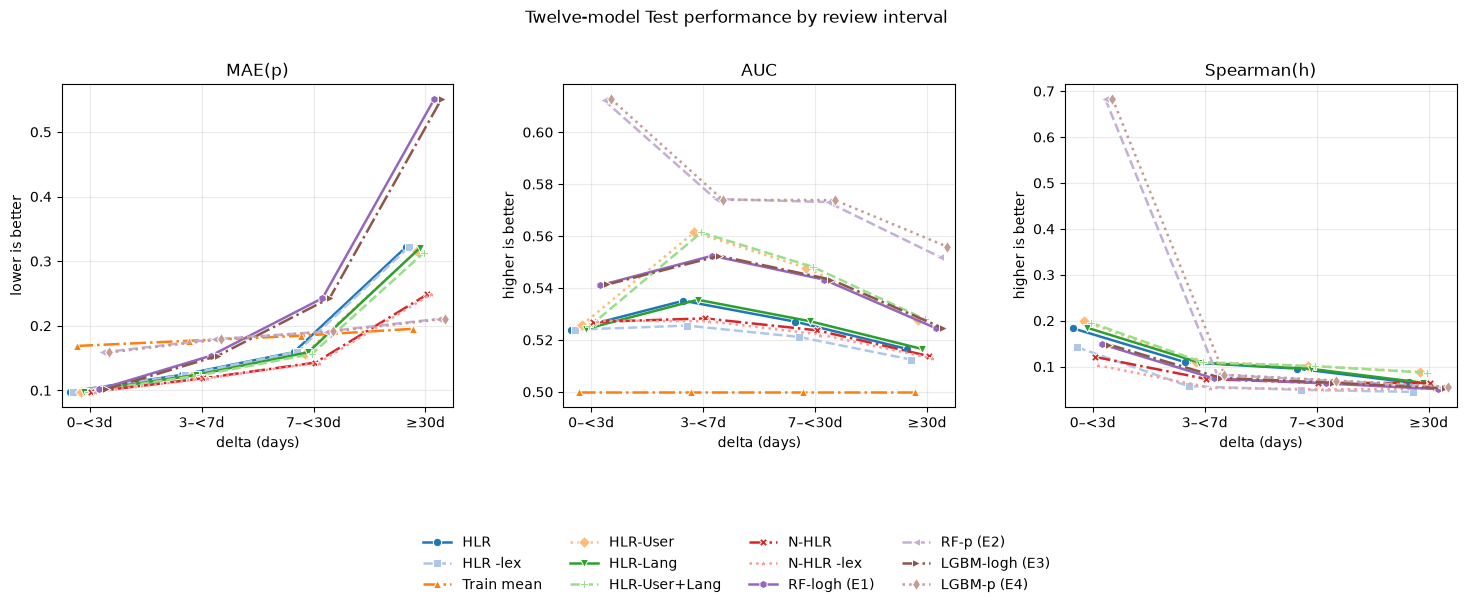

In [3]:
import matplotlib.pyplot as plt

delta_model_order = model_order  # Keep the twelve-model order from section 8.
labels = ["[0, 3) days", "[3, 7) days", "[7, 30) days", "[30, +∞) days"]
test_group_ids = np.searchsorted(np.array([3.0, 7.0, 30.0]),
                                 test_days, side="right")
test_delta_rows = []
for name in delta_model_order:
    p_pred, h_pred = test_predictions[name]
    for group_id, label in enumerate(labels):
        mask = test_group_ids == group_id
        test_delta_rows.append({
            "model": name, "delta interval": label, "rows": int(mask.sum()),
            "MAE(p)": float(np.abs(p_pred[mask] - test_true_p[mask]).mean()),
            "AUC": auc_fixed(np.rint(test_true_p[mask]), p_pred[mask]),
            "Spearman(h)": (np.nan if name == "Train mean" else
                             spearman_with_ties(test_true_h[mask], h_pred[mask])),
        })
final_test_delta = pd.DataFrame(test_delta_rows)
for name in delta_model_order:
    part = final_test_delta[final_test_delta["model"] == name]
    overall = float(final_summary.loc[
        (final_summary["model"] == name) & (final_summary["split"] == "Test"),
        "MAE(p)",
    ].iloc[0])
    assert part["rows"].sum() == n_test
    assert np.isclose(np.average(part["MAE(p)"], weights=part["rows"]), overall)


delta_order = ["[0, 3) days", "[3, 7) days", "[7, 30) days", "[30, +∞) days"]
delta_counts = (final_test_delta[final_test_delta["model"] == "HLR"]
                .set_index("delta interval").loc[delta_order, "rows"])
print("Test counts by delta interval. All twelve models use the same rows.")
display(delta_counts.rename("rows").to_frame())

delta_matrices = {}
for metric in ("MAE(p)", "AUC", "Spearman(h)"):
    matrix = (final_test_delta.pivot(index="model", columns="delta interval",
                                     values=metric)
              .loc[delta_model_order, delta_order])
    assert matrix.shape == (12, 4)
    if metric == "Spearman(h)":
        assert matrix.loc["Train mean"].isna().all()
        assert np.isfinite(matrix.drop(index="Train mean").to_numpy()).all()
    else:
        assert np.isfinite(matrix.to_numpy()).all()
    delta_matrices[metric] = matrix
    print(f"Test {metric}: compare models by row and review intervals by column.")
    display(matrix.round(6))

plot_labels = ["0–<3d", "3–<7d", "7–<30d", "≥30d"]
colors = plt.get_cmap("tab20").colors
markers = ["o", "s", "^", "D", "v", "P", "X", "*", "h", "<", ">", "d"]
line_styles = ["-", "--", "-.", ":", "-", "--", "-.", ":", "-", "--", "-.", ":"]
x_centers = np.arange(4)
fig, axes = plt.subplots(1, 3, figsize=(18, 6.2), sharex=True)
for model_index, model_name in enumerate(delta_model_order):
    # Offset x positions for clarity; retain the actual metric values on y.
    x_positions = x_centers + (model_index - 5.5) * 0.032
    for ax, metric in zip(axes, ("MAE(p)", "AUC", "Spearman(h)")):
        if model_name == "Train mean" and metric == "Spearman(h)":
            continue
        ax.plot(x_positions, delta_matrices[metric].loc[model_name].to_numpy(),
                marker=markers[model_index], linestyle=line_styles[model_index],
                linewidth=1.8, markersize=6, markeredgecolor="white",
                markeredgewidth=0.7, color=colors[model_index],
                label=model_name)
for ax, metric in zip(axes, ("MAE(p)", "AUC", "Spearman(h)")):
    ax.set_title(metric)
    ax.set_xticks(x_centers, plot_labels)
    ax.set_xlim(-0.25, 3.25)
    ax.set_xlabel("delta (days)")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("lower is better")
axes[1].set_ylabel("higher is better")
axes[2].set_ylabel("higher is better")
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="lower center", ncol=4,
           bbox_to_anchor=(0.5, 0.02), frameon=False)
fig.suptitle('Twelve-model Test performance by review interval')
fig.subplots_adjust(bottom=0.34, wspace=0.28, top=0.86)
plt.show()
